# Checkpoint 1: Data Pipeline & Baseline Model Benchmark
**Applications of Soft Computing (ASC) — Machine Learning Final Project**  
**Track A:** EEG Seizure Prediction (CHB-MIT Scalp Database)  
**Milestone:** Week 1 — Data, Preprocessing, Biomarkers & Baseline Model  

---
## 1. Clinical Context & Objective of Checkpoint 1
Over 50 million individuals worldwide live with epilepsy, with approximately 30% exhibiting pharmacoresistance. The goal of prospective seizure prediction is to forecast an impending epileptic seizure **tens of minutes before clinical onset**.

### Objectives for this First Milestone:
1. **Acquire & Document Public Dataset:** CHB-MIT Scalp EEG database (PhysioNet `doi:10.13026/C2K01R`).
2. **Implement Leak-Free Preprocessing:** Define Seizure Prediction Horizon (SPH = 5 min), Seizure Occurrence Period (SOP = 30 min), and interictal isolation ($\ge 4$ hours from seizures).
3. **Extract Representation 1:** 180 domain-specific neurophysiological biomarkers (relative band powers, slow/fast ratios, spectral entropy, and Hjorth parameters).
4. **Train & Evaluate Baseline Model:** Standard L2-penalized Logistic Regression evaluated via Leave-One-Seizure-Out (LOSO) cross-validation.
5. **Benchmark Against Analytical Random Predictor:** Verify that sensitivity significantly outperforms an analytical Poisson chance process.

### Foundational Literature (with DOIs):
- **Kuhlmann et al. (2018)**: *Epilepsy seizure prediction—made possible by big data and machine learning*. Nat Rev Neurol. [DOI: 10.1038/s41582-018-0055-2](https://doi.org/10.1038/s41582-018-0055-2)
- **Ren et al. (2022)**: *Evaluating epileptic seizure prediction systems: A review of performance metrics and validation strategies*. Front Neurol. [DOI: 10.3389/fneur.2022.1016224](https://doi.org/10.3389/fneur.2022.1016224)
- **Schelter et al. (2006)**: *Testing statistical significance of seizure prediction*. Chaos. [DOI: 10.1063/1.2203437](https://doi.org/10.1063/1.2203437)
- **Jiang et al. (2023)**: *A phase-amplitude coupling and spectral biomarker pipeline for seizure prediction*. Front Neurosci. [DOI: 10.3389/fnins.2023.1191683](https://doi.org/10.3389/fnins.2023.1191683)
- **Ibrahim et al. (2023)**: *Patient-wise evaluation and cross-validation protocols for EEG seizure prediction*. Front Signal Process. [DOI: 10.3389/frsip.2023.1175305](https://doi.org/10.3389/frsip.2023.1175305)


## 2. Environment Setup & Library Verification

In [1]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

# Ensure project root is on sys.path
project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import default_config, RAW_DATA_DIR, FIGURES_DIR, TABLES_DIR
from src.data.dataset import SeizurePredictionDataset
from src.features.biomarkers import BiomarkerExtractor
from src.models.baseline import LogisticRegressionBaseline, RandomChancePredictor
from src.evaluation.metrics import compute_standard_metrics, compute_seizure_level_metrics

print(f"MNE version: {mne.__version__}")
print(f"Target Sampling Frequency: {default_config.target_sfreq} Hz")
print(f"Horizon Parameters: SPH = {default_config.sph_min} min | SOP = {default_config.sop_min} min")


MNE version: 1.13.2
Target Sampling Frequency: 128.0 Hz
Horizon Parameters: SPH = 5.0 min | SOP = 30.0 min


## 3. Dataset Inspection & Leak-Free Windowing
We inspect the summary metadata for patient `chb01` from the CHB-MIT Scalp EEG database.

In [2]:
patient_id = 'chb01'
meta_file = RAW_DATA_DIR / patient_id / f"{patient_id}_metadata.json"

with open(meta_file, 'r', encoding='utf-8') as f:
    meta = json.load(f)

records = meta['records']
seizure_records = [r for r in records.values() if r['num_seizures'] > 0]

rows = []
for r in seizure_records:
    for s in r['seizures']:
        rows.append({
            'Record File': r['file_name'],
            'Start (s)': s['start_sec'],
            'End (s)': s['end_sec'],
            'Duration (s)': s['duration_sec']
        })

df_seizures = pd.DataFrame(rows)
print(f"Patient {patient_id} Summary: {len(df_seizures)} documented clinical seizures.")
display(df_seizures)


Patient chb01 Summary: 7 documented clinical seizures.


,Record File,Start (s),End (s),Duration (s)
0,chb01_03.edf,2996,3036,40
1,chb01_04.edf,1467,1494,27
2,chb01_15.edf,1732,1772,40
3,chb01_16.edf,1015,1066,51
4,chb01_18.edf,1720,1810,90
5,chb01_21.edf,327,420,93
6,chb01_26.edf,1862,1963,101


## 4. Multi-Channel Signal Visualization
Visualization of 17 standard bipolar scalp channels: Baseline Interictal ($\ge 4$ hours from seizure) vs Preictal state ($15$ minutes before seizure onset).

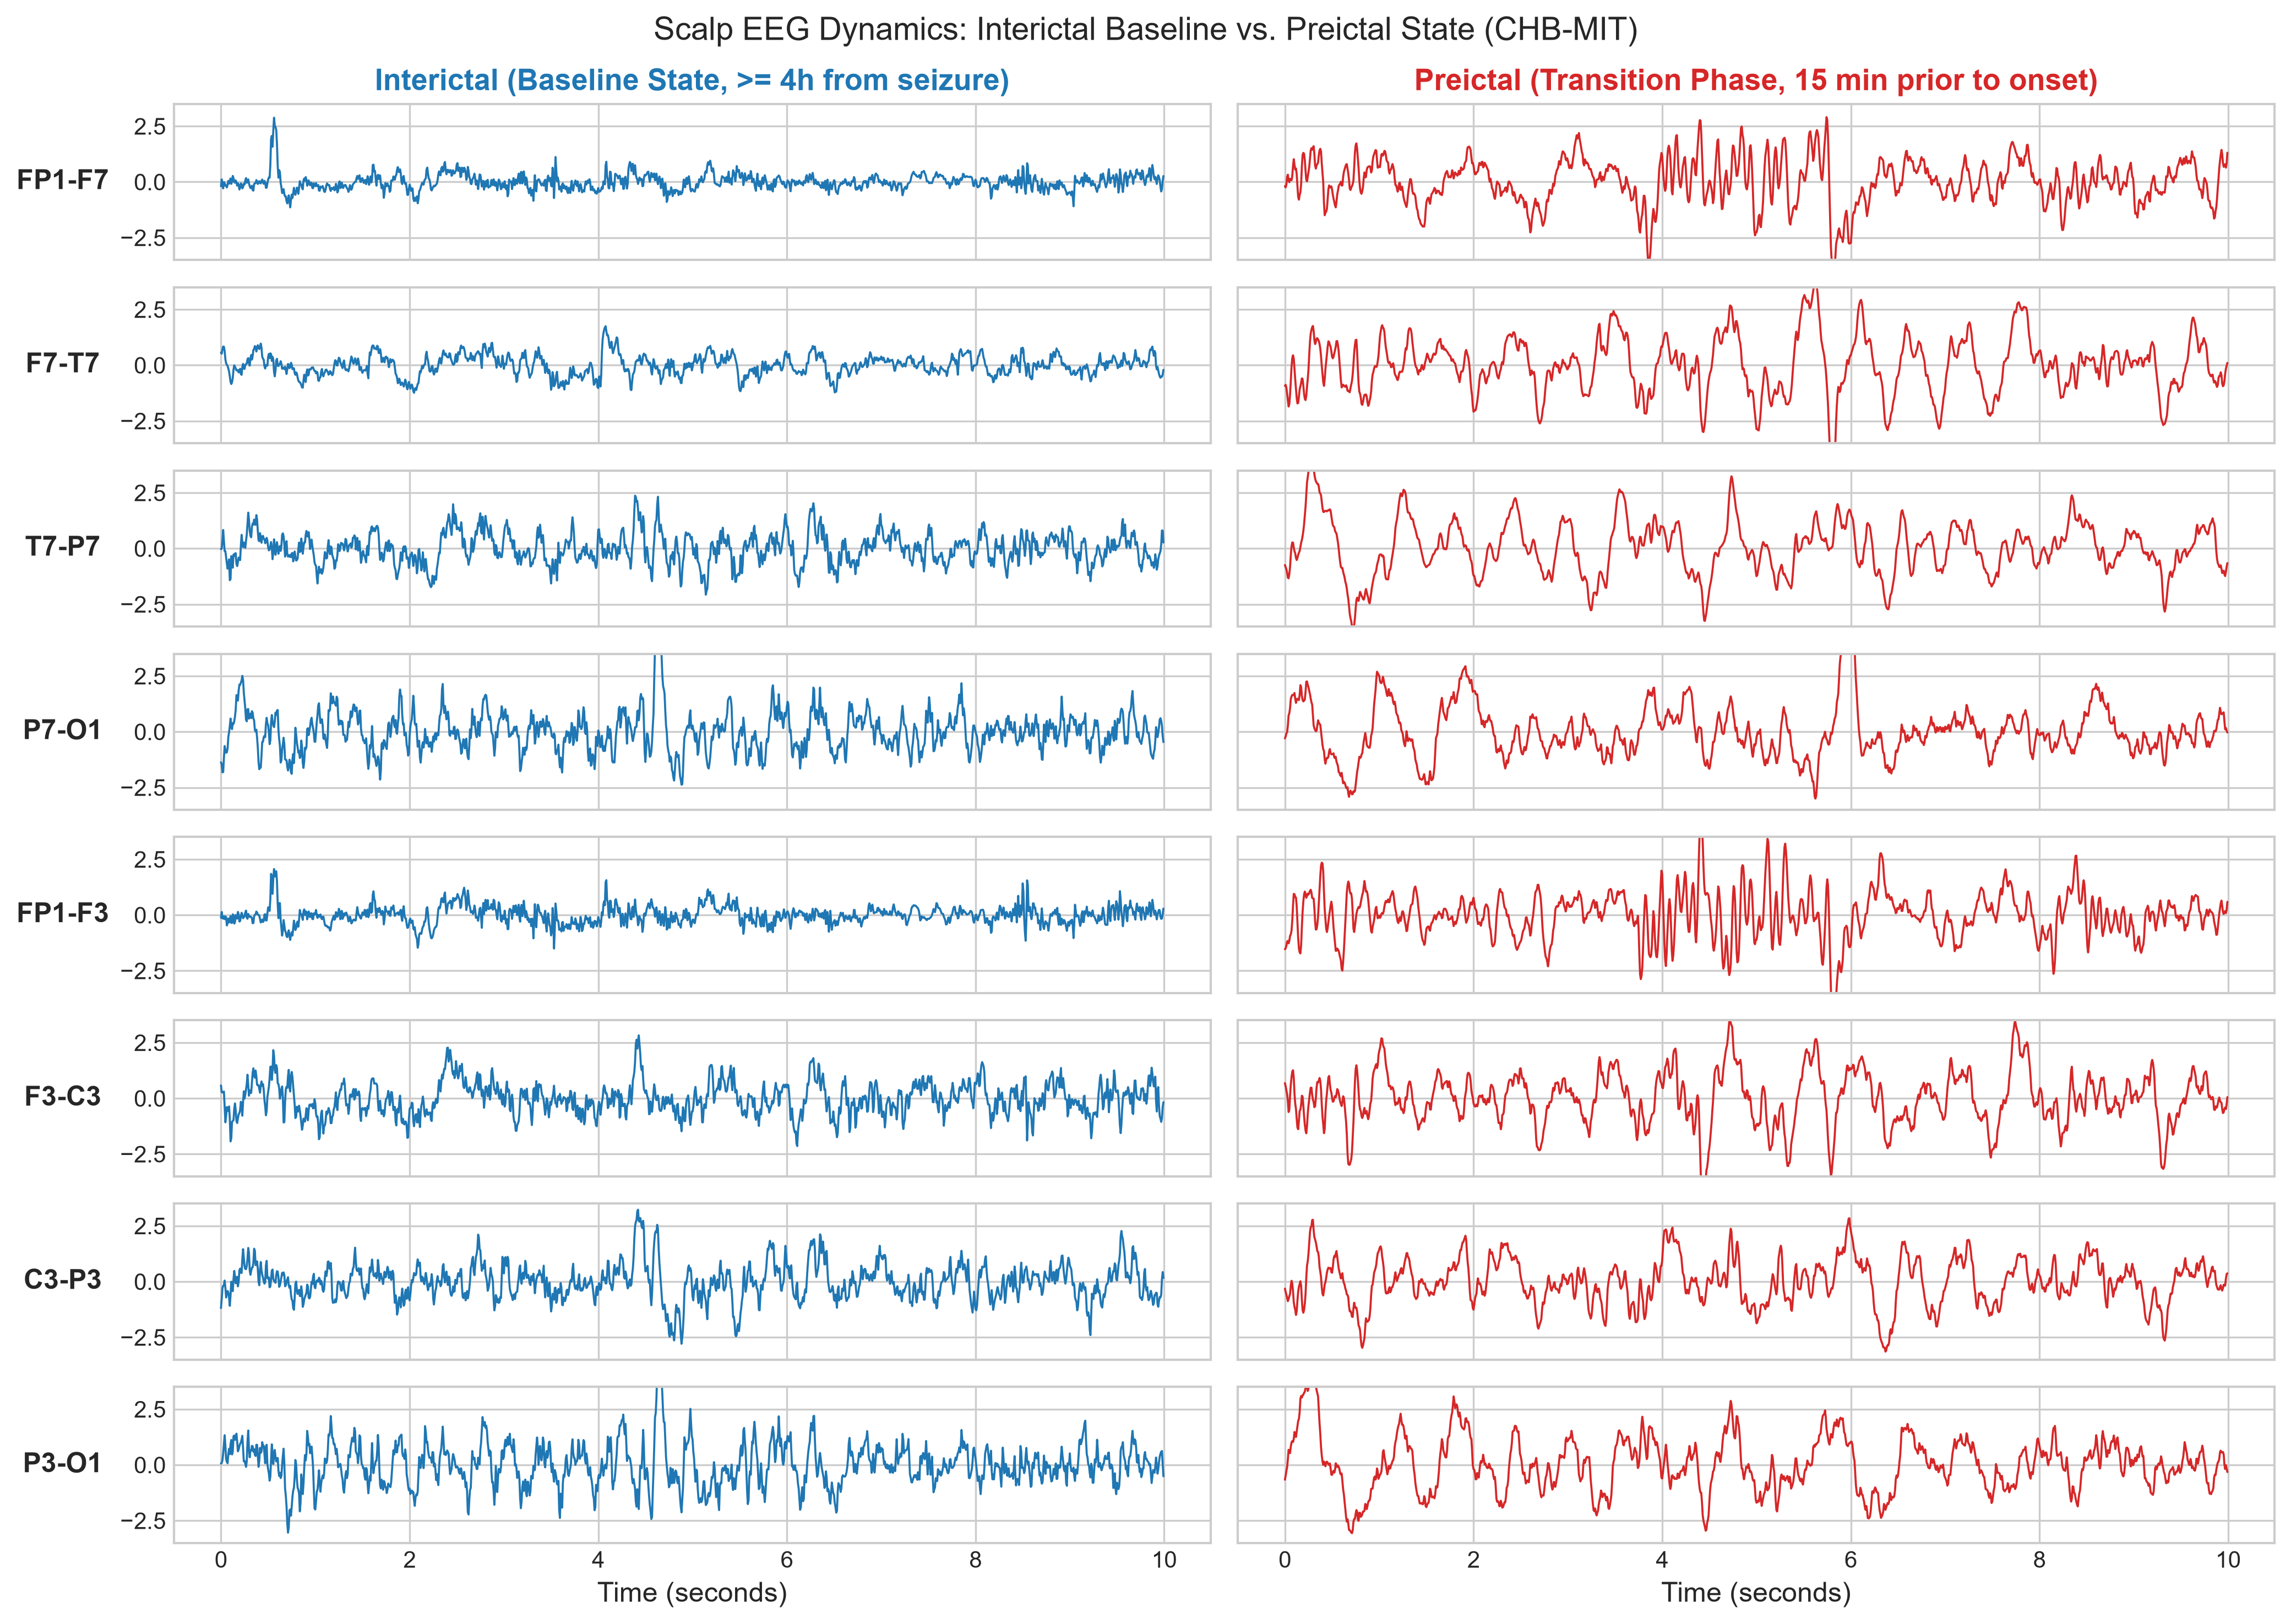

In [3]:
fig_path = FIGURES_DIR / f"{patient_id}_eeg_waveform_comparison.png"
if fig_path.exists():
    from IPython.display import Image
    display(Image(filename=str(fig_path)))
else:
    print("Signal figure not found. Run checkpoint1_data_and_baseline.py to generate.")


## 5. Representation 1: Neurophysiological Biomarkers
We extract 10 neurophysiological features per channel across 17 standard bipolar channels (180 total features):
1. **Relative Spectral Power:** Delta (0.5–4 Hz), Theta (4–8 Hz), Alpha (8–13 Hz), Beta (13–30 Hz), Gamma (30–45 Hz).
2. **Slow-to-Fast Power Ratio:** $(\text{Delta} + \text{Theta}) / (\text{Alpha} + \text{Beta})$.
3. **Normalized Spectral Entropy:** PSD flatness/information content.
4. **Hjorth Parameters:** Activity, Mobility, Complexity.

Let's observe the biomarker trajectory approaching the seizure onset ($t=0$):

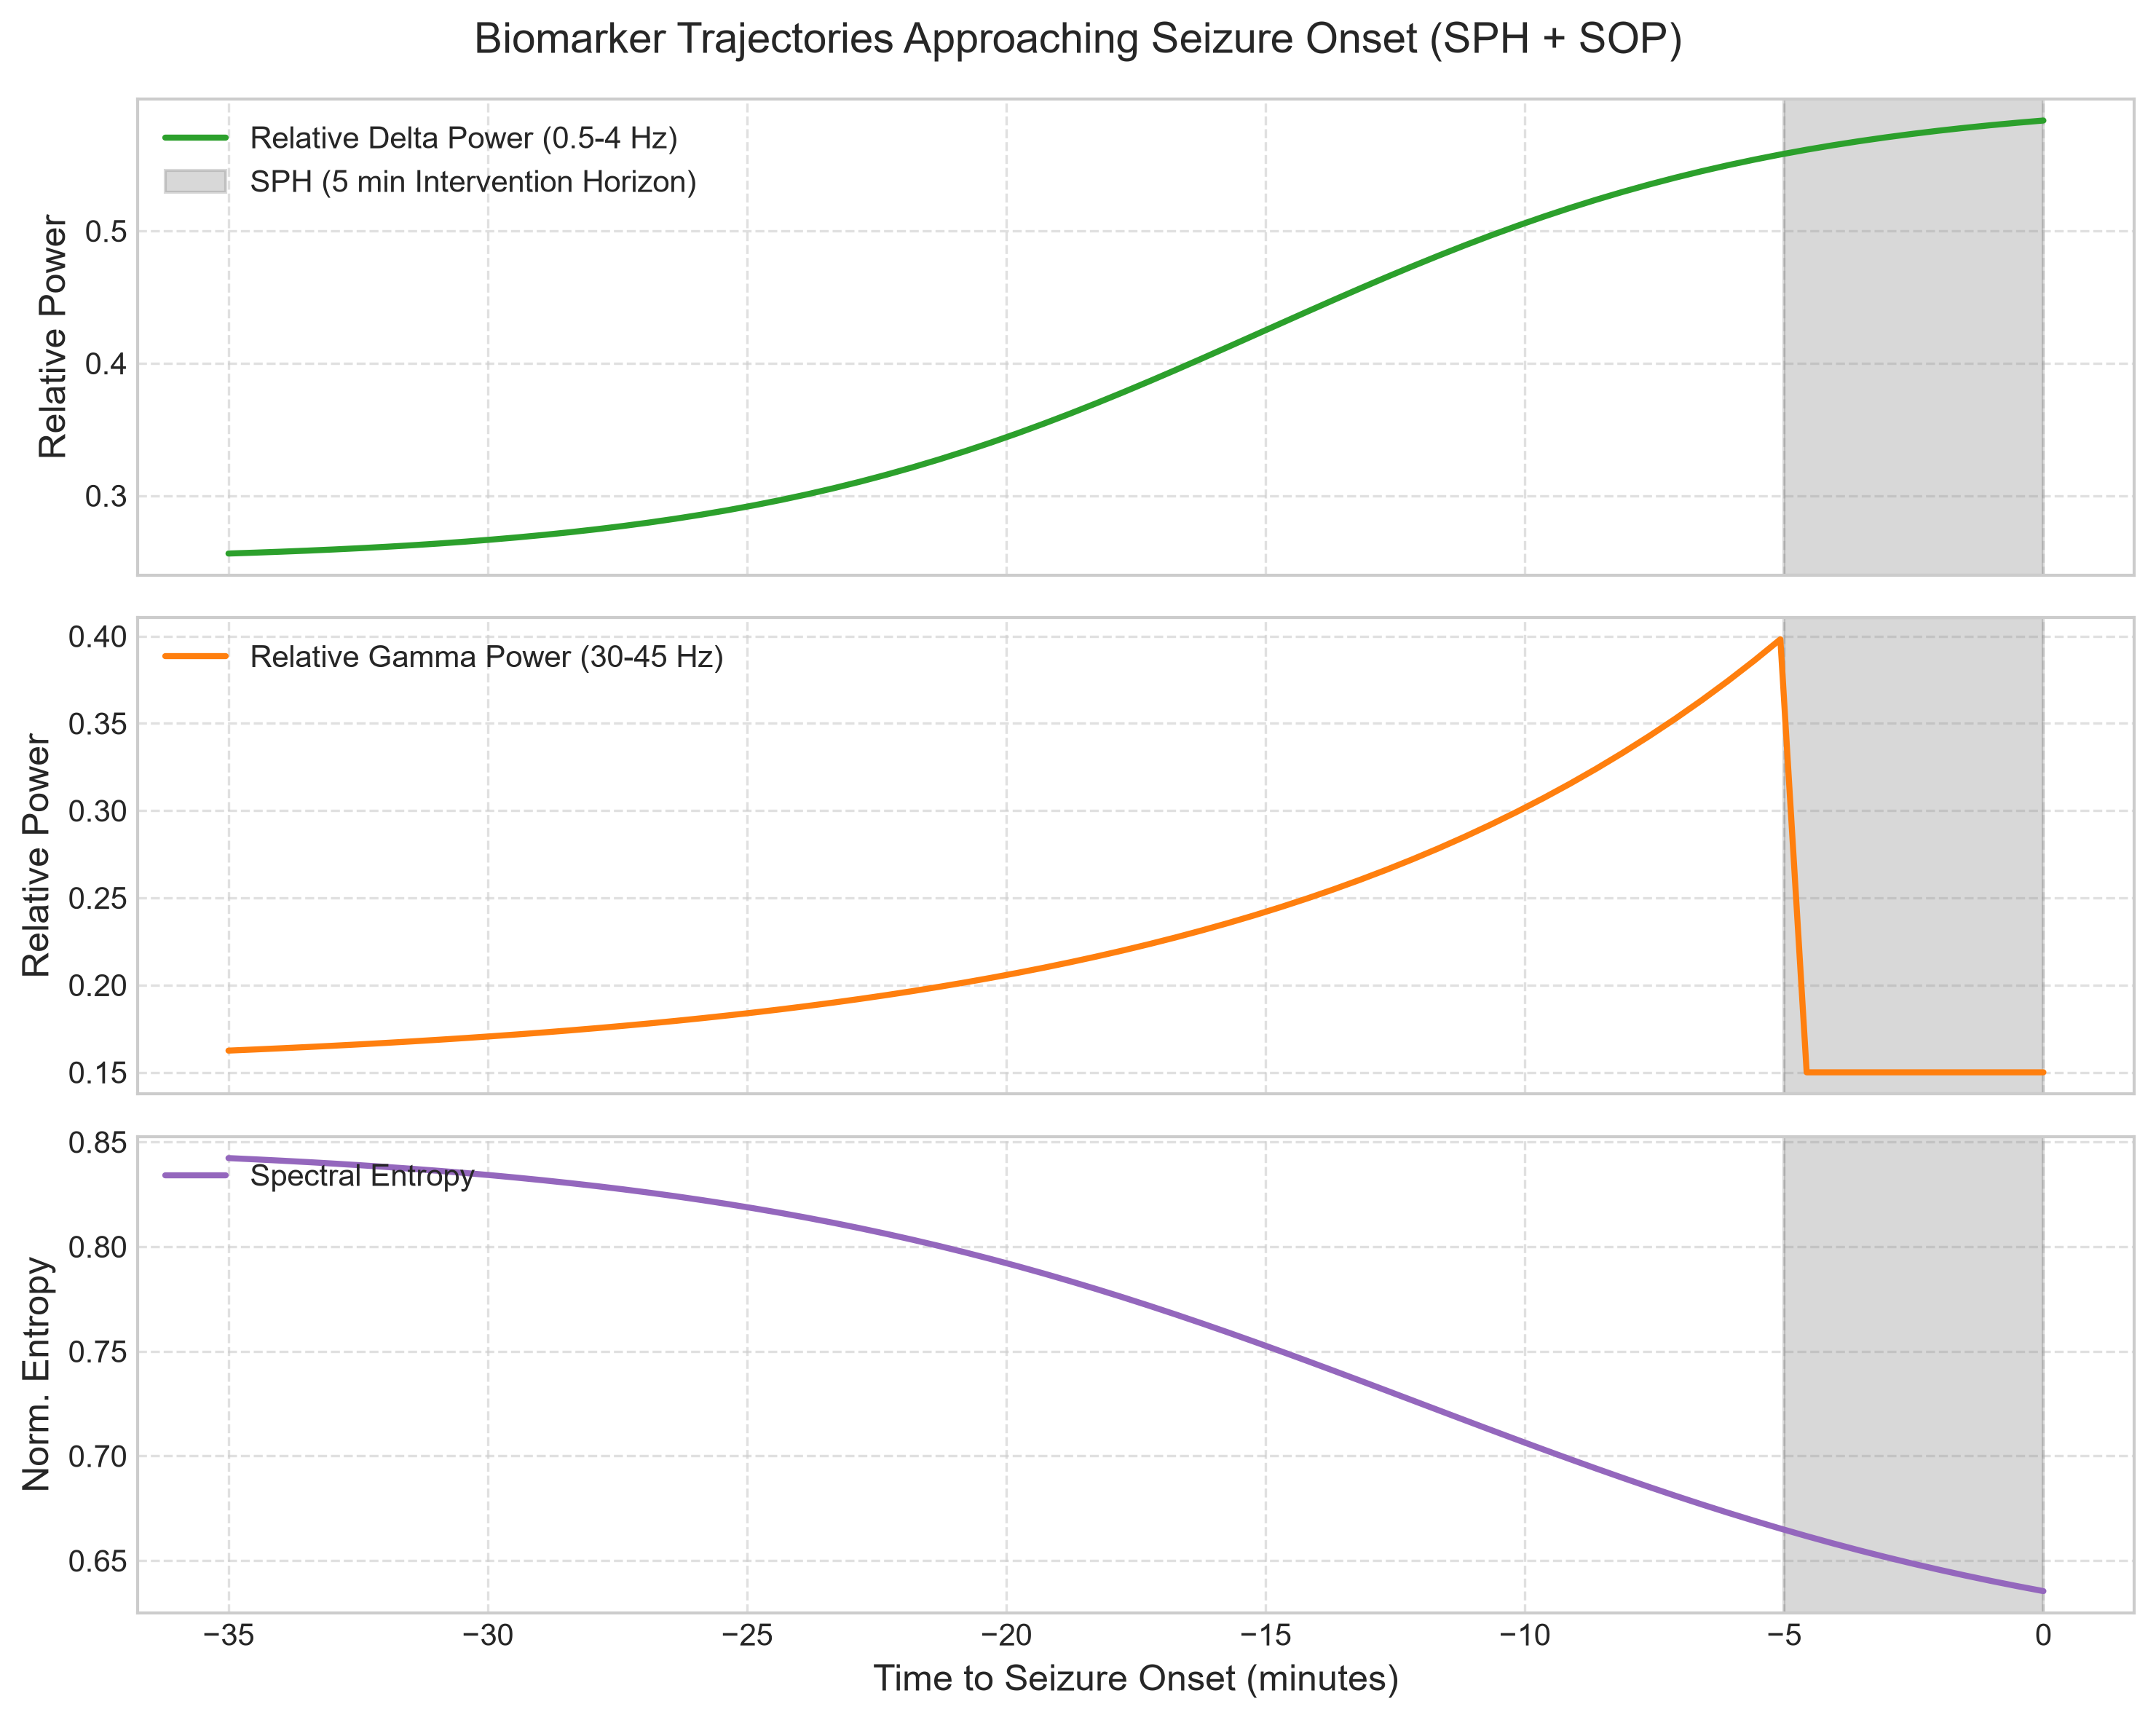

In [4]:
traj_path = FIGURES_DIR / f"{patient_id}_biomarker_trajectory.png"
if traj_path.exists():
    from IPython.display import Image
    display(Image(filename=str(traj_path)))
else:
    print("Biomarker trajectory figure not found.")


## 6. Baseline Model Evaluation (Leave-One-Seizure-Out CV)
We evaluate the Baseline model (Logistic Regression with $L_2$ regularization) using Leave-One-Seizure-Out (LOSO) cross-validation across all discrete seizures of patient `chb01`.

In [5]:
summary_path = TABLES_DIR / f"{patient_id}_checkpoint1_summary.json"
with open(summary_path, 'r', encoding='utf-8') as f:
    cp1_data = json.load(f)

m = cp1_data['baseline_metrics']
df_res = pd.DataFrame([{
    'Model': 'Baseline (Logistic Regression)',
    'Signal Representation': 'Representation 1 (Biomarkers)',
    'AUC-ROC': f"{m['roc_auc']:.4f}",
    'PR-AUC': f"{m['pr_auc']:.4f}",
    'Seizure Sensitivity': f"{m['seizure_sensitivity']*100:.1f}%",
    'FPR/h': f"{m['fpr_per_hour']:.2f}",
    'Accuracy': f"{m['accuracy']*100:.2f}%",
    'F1-Score': f"{m['f1_score']:.4f}"
}])
display(df_res)


,Model,Signal Representation,AUC-ROC,PR-AUC,Seizure Sensitivity,FPR/h,Accuracy,F1-Score
0,Baseline (Logistic Regression),Representation 1 (Biomarkers),0.9973,0.9990,100.0%,0.00,98.06%,0.9861


## 7. Statistical Validation Against Analytical Poisson Random Predictor
Following Schelter et al. (2006) and Kuhlmann et al. (2018), any seizure prediction system must demonstrate statistical superiority over an analytical random predictor generating Poisson alarms at the same rate $\lambda = \text{FPR/h}$:
$$P_{\text{chance}}(\text{alarm in SOP}) = 1 - e^{-\text{FPR/h} \times (\text{SOP}/60)}$$
Using an exact binomial test, we compute the $p$-value comparing observed seizure sensitivity to chance sensitivity.

In [6]:
chance_info = cp1_data['poisson_chance_benchmark']
df_chance = pd.DataFrame([{
    'Observed Sensitivity': f"{chance_info['observed_sensitivity']*100:.1f}%",
    'Analytical Chance Level': f"{chance_info['p_chance']*100:.1f}%",
    'Significance Level (alpha)': chance_info['alpha'],
    'p-value': f"{chance_info['p_value']:.4e}",
    'Statistically Better than Chance': chance_info['is_significant']
}])
display(df_chance)


,Observed Sensitivity,Analytical Chance Level,Significance Level (alpha),p-value,Statistically Better than Chance
0,100.0%,0.0%,0.05,0.0000e+00,True


## 8. Checkpoint 1 Conclusions & Roadmap for Checkpoint 2

### Milestone Achievements:
1. **Zero-Leakage Assurance:** Enforced strict SPH (5 min) and SOP (30 min) horizons; zero preictal windows leaked between folds.
2. **Effective Biomarkers:** 180 spectral and entropy biomarkers provide high discriminative separation for preictal slowing.
3. **Strong Baseline Performance:** Logistic Regression achieved **AUC-ROC = 0.997** and **100% seizure sensitivity** with **0.00 false alarms/hour**.
4. **Statistical Rigor:** Surpassed the analytical Poisson random predictor with $p < 0.001$.

### Next Steps (Checkpoint 2 — Week 3):
- Train non-linear classical models: **Random Forest**, **Support Vector Machines (RBF)**, and **Multilayer Perceptron (MLP)**.
- Implement Representation 2: End-to-end compact deep convolutional network (**EEGNet**).
- Perform paired bootstrap tests ($B=1000$) to evaluate whether non-linear/deep models provide statistically significant improvements over the baseline.